### Use SHAP values to interpret model predictions by manually computing Shapley values, visualizing their impact on individual predictions without using built-in SHAP libraries, and analyzing feature contribution variability.

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools
import math
import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv("heart_disease.csv")

display(df.head())
print("Dataset shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\nTarget distribution:\n", df["target"].value_counts())


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


Dataset shape: (25, 14)

Missing values:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Target distribution:
 target
1    16
0     9
Name: count, dtype: int64


In [17]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

df = df.drop_duplicates().copy()
df = df.dropna(subset=["target"])

X = df.drop(columns=["target"])
y = df["target"]

X = pd.get_dummies(X, drop_first=True)
X = X.fillna(X.median(numeric_only=True))

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (20, 13)
Testing data: (5, 13)


In [18]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.6
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         2
           1       0.60      1.00      0.75         3

    accuracy                           0.60         5
   macro avg       0.30      0.50      0.38         5
weighted avg       0.36      0.60      0.45         5



In [19]:
feature_names = X_train.columns.tolist()

background = X_train.sample(
    n=min(10, len(X_train)),
    random_state=42
).to_numpy()

sample = X_test.iloc[[0]].to_numpy()

print("Number of features:", len(feature_names))
print("Selected sample shape:", sample.shape)
print("Actual target:", y_test.iloc[0])
print("Predicted target:", model.predict(sample)[0])


Number of features: 13
Selected sample shape: (1, 13)
Actual target: 1
Predicted target: 1


In [20]:

def manual_shapley(model, background, sample):
    n_features = sample.shape[1]
    n_background = len(background)

    if n_features > 15:
        raise ValueError(
            "Exact Shapley calculation is expensive for more than 15 features."
        )

    subsets = [
        tuple(i for i in range(n_features) if mask & (1 << i))
        for mask in range(1 << n_features)
    ]

    hybrid_data = []

    for subset in subsets:
        hybrid = background.copy()

        if subset:
            hybrid[:, list(subset)] = sample[0, list(subset)]

        hybrid_data.append(hybrid)

    hybrid_data = np.vstack(hybrid_data)

    predictions = model.predict_proba(hybrid_data)[:, 1]

    values = {
        subset: predictions[
            i * n_background:(i + 1) * n_background
        ].mean()
        for i, subset in enumerate(subsets)
    }

    shap_values = np.zeros(n_features)
    all_features = set(range(n_features))

    for i in range(n_features):
        remaining = all_features - {i}

        for size in range(n_features):
            for subset in itertools.combinations(remaining, size):
                subset = tuple(sorted(subset))
                with_feature = tuple(sorted(subset + (i,)))

                weight = (
                    math.factorial(size)
                    * math.factorial(n_features - size - 1)
                    / math.factorial(n_features)
                )

                shap_values[i] += weight * (
                    values[with_feature] - values[subset]
                )

    base_value = values[()]
    prediction = model.predict_proba(sample)[0, 1]

    return base_value, shap_values, prediction


In [21]:
base_value, shap_values, prediction = manual_shapley(
    model, background, sample
)

explanation = pd.DataFrame({
    "Feature": feature_names,
    "Feature Value": sample[0],
    "SHAP Value": shap_values
})

explanation["Absolute SHAP"] = explanation["SHAP Value"].abs()
explanation = explanation.sort_values(
    "Absolute SHAP",
    ascending=False
)

print("Base probability:", round(base_value, 4))
print("Predicted probability:", round(prediction, 4))
print("Sum of base value and SHAP values:",
      round(base_value + shap_values.sum(), 6))

display(explanation)


Base probability: 0.704
Predicted probability: 0.73
Sum of base value and SHAP values: 0.73


,Feature,Feature Value,SHAP Value,Absolute SHAP
6,restecg,0.0,-0.125333,0.125333
0,age,41.0,0.045667,0.045667
12,thal,2.0,0.035133,0.035133
3,trestbps,130.0,0.018300,0.018300
8,exang,0.0,0.017333,0.017333
9,oldpeak,1.4,0.016750,0.016750
10,slope,2.0,0.013133,0.013133
2,cp,1.0,-0.013000,0.013000
11,ca,0.0,0.012083,0.012083
7,thalach,172.0,0.009383,0.009383


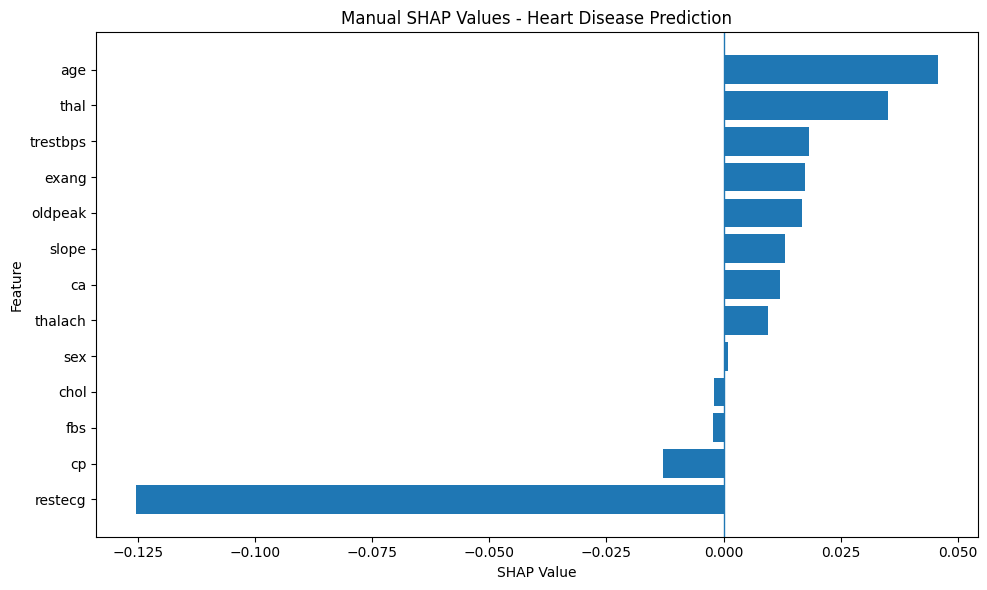

In [22]:
plot_data = explanation.sort_values("SHAP Value")

plt.figure(figsize=(10, 6))
plt.barh(
    plot_data["Feature"],
    plot_data["SHAP Value"]
)
plt.axvline(0, linewidth=1)
plt.xlabel("SHAP Value")
plt.ylabel("Feature")
plt.title("Manual SHAP Values - Heart Disease Prediction")
plt.tight_layout()
plt.show()


In [23]:
n_samples = min(5, len(X_test))
all_shap_values = []

for i in range(n_samples):
    sample_i = X_test.iloc[[i]].to_numpy()

    _, values, _ = manual_shapley(
        model, background, sample_i
    )

    all_shap_values.append(values)

shap_df = pd.DataFrame(
    all_shap_values,
    columns=feature_names
)

variability = pd.DataFrame({
    "Mean SHAP": shap_df.mean(),
    "Mean Absolute SHAP": shap_df.abs().mean(),
    "SHAP Standard Deviation": shap_df.std(ddof=0)
}).sort_values(
    "Mean Absolute SHAP",
    ascending=False
)

display(variability)


,Mean SHAP,Mean Absolute SHAP,SHAP Standard Deviation
restecg,-0.023977,0.115590,0.113269
age,0.024007,0.056460,0.052746
thal,0.013550,0.050903,0.053642
cp,-0.014417,0.026250,0.031545
thalach,-0.010990,0.023777,0.022723
exang,0.009567,0.023533,0.022321
slope,-0.005023,0.018177,0.017798
trestbps,0.003877,0.017043,0.019564
oldpeak,0.014117,0.014117,0.002849
ca,0.012067,0.012067,0.000370


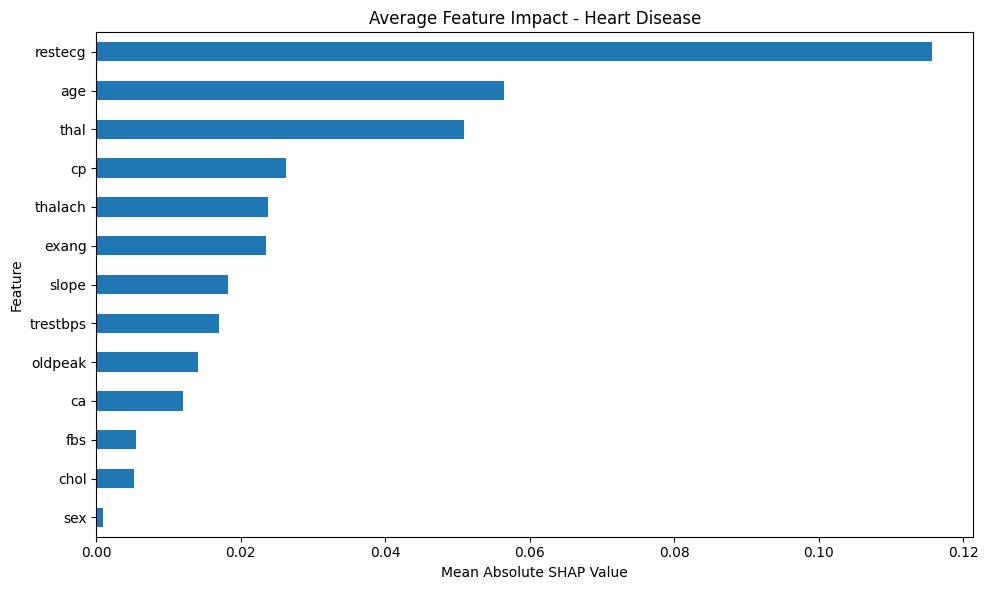

In [24]:
variability["Mean Absolute SHAP"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Average Feature Impact - Heart Disease")
plt.tight_layout()
plt.show()


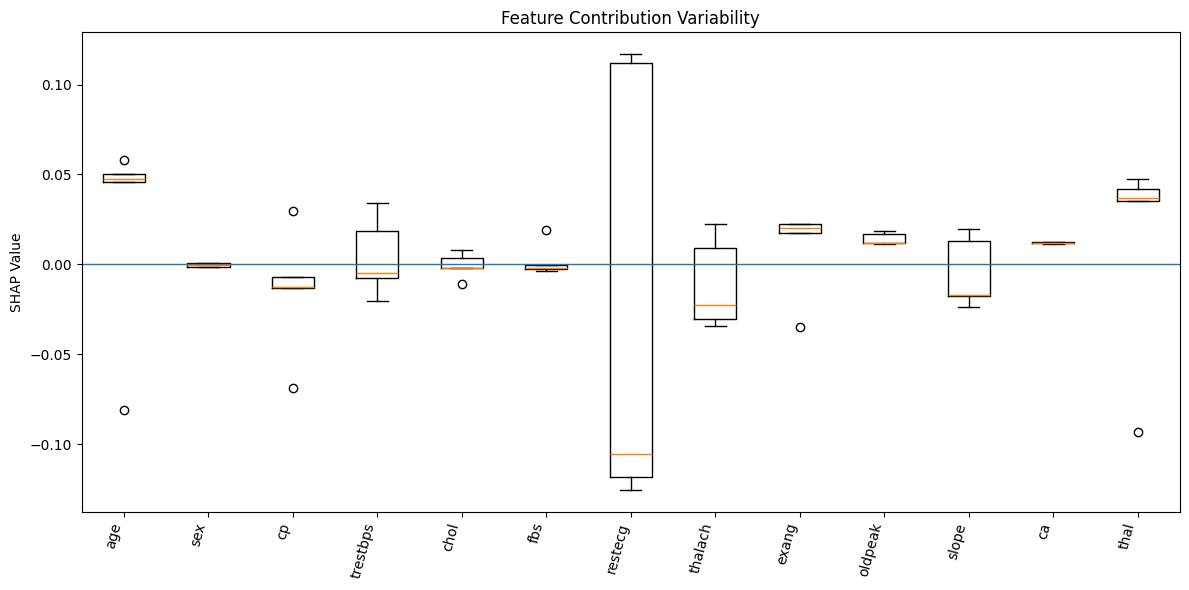

In [25]:
plt.figure(figsize=(12, 6))

plt.boxplot(
    [shap_df[col].values for col in feature_names],
    tick_labels=feature_names
)

plt.axhline(0, linewidth=1)
plt.ylabel("SHAP Value")
plt.title("Feature Contribution Variability")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()


### Implement LIME to explain individual predictions by constructing synthetic perturbed datasets, training surrogate models manually, and validating explanations through independent verification techniques.

In [27]:
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    accuracy_score
)
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances

In [28]:
feature_names = X_train.columns.tolist()

X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

patient_index = 0
patient = X_test.iloc[patient_index].to_numpy(dtype=float)

rng = np.random.default_rng(42)
n_samples = 2000

train_mean = X_train.mean().to_numpy(dtype=float)
train_std = X_train.std(ddof=0).to_numpy(dtype=float)

train_std[train_std == 0] = 1

noise = rng.normal(
    loc=0,
    scale=train_std,
    size=(n_samples, len(feature_names))
)

synthetic_data = patient + noise

lower = X_train.min().to_numpy(dtype=float)
upper = X_train.max().to_numpy(dtype=float)

synthetic_data = np.clip(
    synthetic_data,
    lower,
    upper
)

synthetic_df = pd.DataFrame(
    synthetic_data,
    columns=feature_names
)

print("Patient feature shape:", patient.shape)
print("Synthetic dataset shape:", synthetic_df.shape)

display(synthetic_df.head())


Patient feature shape: (13,)
Synthetic dataset shape: (2000, 13)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,43.279225,0.000000,1.825496,144.542223,168.000000,0.000000,0.063920,166.659829,0.000000,0.374403,2.000000,0.797000,2.042280
1,49.431546,0.214240,0.054778,135.701315,168.000000,0.380380,0.000000,168.878357,0.000000,2.869836,1.889644,0.000000,1.774525
2,44.981570,0.167468,1.454006,136.660993,320.264839,0.000000,0.000000,158.258381,0.266727,2.757340,1.918625,0.000000,1.472074
3,45.866308,0.340602,1.597470,119.710447,216.603474,0.050526,0.109344,186.715217,0.096820,2.216244,2.000000,0.296259,2.404222
4,37.000000,0.000000,0.482590,120.122207,189.063196,0.647329,0.000000,187.000000,0.000000,0.997375,2.000000,0.600699,2.455407


In [29]:
synthetic_predictions = model.predict_proba(
    synthetic_df
)[:, 1]

original_prediction = model.predict_proba(
    pd.DataFrame([patient], columns=feature_names)
)[0, 1]

print("Original model probability:", round(original_prediction, 4))
print("Original model class:", model.predict(
    pd.DataFrame([patient], columns=feature_names)
)[0])


Original model probability: 0.73
Original model class: 1


In [30]:
scaler = StandardScaler()
scaler.fit(X_train)

patient_scaled = scaler.transform(
    pd.DataFrame([patient], columns=feature_names)
)

synthetic_scaled = scaler.transform(synthetic_df)

distances = pairwise_distances(
    synthetic_scaled,
    patient_scaled
).ravel()

kernel_width = np.sqrt(len(feature_names)) * 0.75

weights = np.sqrt(
    np.exp(-(distances ** 2) / (kernel_width ** 2))
)

print("Minimum distance:", round(distances.min(), 4))
print("Maximum distance:", round(distances.max(), 4))
print("Average weight:", round(weights.mean(), 4))


Minimum distance: 0.9402
Maximum distance: 4.8308
Average weight: 0.5993


In [31]:
surrogate = Ridge(alpha=1.0)

surrogate.fit(
    synthetic_scaled,
    synthetic_predictions,
    sample_weight=weights
)

surrogate_prediction = surrogate.predict(
    patient_scaled
)[0]

local_predictions = surrogate.predict(synthetic_scaled)

local_r2 = r2_score(
    synthetic_predictions,
    local_predictions,
    sample_weight=weights
)

print("Original prediction:", round(original_prediction, 4))
print("Surrogate prediction:", round(surrogate_prediction, 4))
print("Weighted local R²:", round(local_r2, 4))


Original prediction: 0.73
Surrogate prediction: 0.6698
Weighted local R²: 0.6733


In [32]:
contributions = (
    surrogate.coef_ * patient_scaled[0]
)

lime_explanation = pd.DataFrame({
    "Feature": feature_names,
    "Patient Value": patient,
    "Coefficient": surrogate.coef_,
    "Contribution": contributions
})

lime_explanation["Absolute Contribution"] = (
    lime_explanation["Contribution"].abs()
)

lime_explanation = lime_explanation.sort_values(
    "Absolute Contribution",
    ascending=False
)

display(lime_explanation)


,Feature,Patient Value,Coefficient,Contribution,Absolute Contribution
6,restecg,0.0,0.137908,-0.137908,0.137908
11,ca,0.0,-0.054748,0.026714,0.026714
12,thal,2.0,-0.038523,0.018049,0.018049
8,exang,0.0,-0.028598,0.016511,0.016511
2,cp,1.0,0.051312,-0.013994,0.013994
10,slope,2.0,0.010966,0.010749,0.010749
3,trestbps,130.0,-0.017922,0.009331,0.009331
0,age,41.0,-0.004636,0.009266,0.009266
1,sex,0.0,0.005151,-0.007868,0.007868
9,oldpeak,1.4,-0.041176,0.003596,0.003596


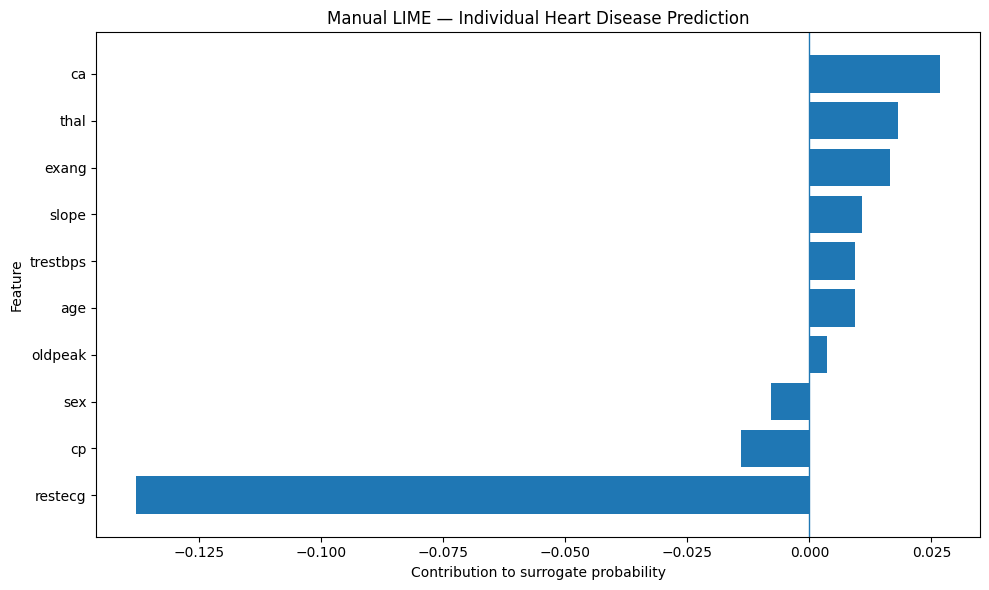

In [33]:
top_features = lime_explanation.head(10).sort_values(
    "Contribution"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Contribution"]
)

plt.axvline(0, linewidth=1)
plt.xlabel("Contribution to surrogate probability")
plt.ylabel("Feature")
plt.title("Manual LIME — Individual Heart Disease Prediction")
plt.tight_layout()
plt.show()


In [34]:
prediction_difference = abs(
    original_prediction - surrogate_prediction
)

print("Original probability:", round(original_prediction, 4))
print("Surrogate probability:", round(surrogate_prediction, 4))
print("Absolute prediction difference:",
      round(prediction_difference, 4))

print(
    "Explanation check:",
    "Close approximation" if prediction_difference < 0.05
    else "Large difference; inspect the explanation"
)


Original probability: 0.73
Surrogate probability: 0.6698
Absolute prediction difference: 0.0602
Explanation check: Large difference; inspect the explanation


In [35]:
n_validation = 500

validation_noise = rng.normal(
    0,
    train_std,
    size=(n_validation, len(feature_names))
)

validation_data = np.clip(
    patient + validation_noise,
    lower,
    upper
)

validation_df = pd.DataFrame(
    validation_data,
    columns=feature_names
)

validation_targets = model.predict_proba(
    validation_df
)[:, 1]

validation_scaled = scaler.transform(validation_df)

validation_distances = pairwise_distances(
    validation_scaled,
    patient_scaled
).ravel()

validation_weights = np.exp(
    -(validation_distances ** 2) / (kernel_width ** 2)
)

validation_surrogate = surrogate.predict(validation_scaled)

validation_r2 = r2_score(
    validation_targets,
    validation_surrogate,
    sample_weight=validation_weights
)

validation_mae = np.average(
    np.abs(validation_targets - validation_surrogate),
    weights=validation_weights
)

print("Independent weighted R²:", round(validation_r2, 4))
print("Independent weighted MAE:", round(validation_mae, 4))


Independent weighted R²: 0.6562
Independent weighted MAE: 0.0595


In [36]:
def fit_lime_once(seed, n_samples=1500):
    local_rng = np.random.default_rng(seed)

    noise = local_rng.normal(
        0,
        train_std,
        size=(n_samples, len(feature_names))
    )

    perturbed = np.clip(
        patient + noise,
        lower,
        upper
    )

    perturbed_df = pd.DataFrame(
        perturbed,
        columns=feature_names
    )

    targets = model.predict_proba(
        perturbed_df
    )[:, 1]

    perturbed_scaled = scaler.transform(perturbed_df)

    distances = pairwise_distances(
        perturbed_scaled,
        patient_scaled
    ).ravel()

    weights = np.exp(
        -(distances ** 2) / (kernel_width ** 2)
    )

    local_model = Ridge(alpha=1.0)

    local_model.fit(
        perturbed_scaled,
        targets,
        sample_weight=weights
    )

    return local_model.coef_ * patient_scaled[0]


stability_values = np.vstack([
    fit_lime_once(seed)
    for seed in range(5)
])

stability_df = pd.DataFrame(
    stability_values,
    columns=feature_names
)

stability_summary = pd.DataFrame({
    "Mean Contribution": stability_df.mean(),
    "Contribution Std": stability_df.std(ddof=0)
})

stability_summary["Mean Absolute Contribution"] = (
    stability_df.abs().mean()
)

display(
    stability_summary.sort_values(
        "Mean Absolute Contribution",
        ascending=False
    )
)


,Mean Contribution,Contribution Std,Mean Absolute Contribution
restecg,-0.135854,0.004269,0.135854
ca,0.026285,0.002738,0.026285
thal,0.018264,0.001114,0.018264
slope,0.015776,0.001702,0.015776
cp,-0.015536,0.000930,0.015536
exang,0.013576,0.001304,0.013576
trestbps,0.011286,0.000670,0.011286
age,0.007617,0.006200,0.007789
sex,0.002645,0.005264,0.005396
oldpeak,0.003615,0.000179,0.003615
